# Diagnóstico de Cáncer de Mama Wisconsin usando Regresión Logística

**Fuente original:** https://www.geeksforgeeks.org/machine-learning/ml-kaggle-breast-cancer-wisconsin-diagnosis-using-logistic-regression/

**Modificador y ejecutor:** Carlos Francisco Montoya Urzúa

---

El dataset **Breast Cancer Wisconsin Diagnosis** se usa frecuentemente en machine learning para clasificar tumores mamarios como **malignos** (cancerosos) o **benignos** (no cancerosos), basándose en características extraídas de imágenes de masas mamarias.

En este notebook aplicaremos el algoritmo de **Regresión Logística** para clasificación binaria y predecir la naturaleza de los tumores. Este algoritmo es ideal para tareas donde el objetivo es clasificar datos en dos categorías.

Recorreremos los pasos de preprocesamiento de los datos, entrenamiento del modelo y evaluación de su rendimiento, demostrando cómo este modelo puede funcionar en la detección temprana y el diagnóstico del cáncer de mama.

---
**Descarga el dataset:** https://media.geeksforgeeks.org/wp-content/uploads/20240919120521/data.csv

## Implementación de la Detección de Cáncer de Mama con Regresión Logística

A continuación se muestra la implementación paso a paso.

### 1. Cargar las Librerías

Utilizaremos **numpy**, **pandas**, **matplotlib** y **scikit-learn**.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

### 2. Cargar el Dataset

In [5]:
"""data = pd.read_csv("data.csv")
print(data.head)"""

import kagglehub
import os

# Download latest version
path = kagglehub.dataset_download("uciml/breast-cancer-wisconsin-data")

print("Path to dataset files:", path)

csv_path = os.path.join(
    path,
    "data.csv"
)

data = pd.read_csv(
    csv_path,
    encoding='latin-1',
    header=0  #Esto asegura que tome la primer fila como encabezados
)

print(data.head())

Using Colab cache for faster access to the 'breast-cancer-wisconsin-data' dataset.
Path to dataset files: /kaggle/input/breast-cancer-wisconsin-data
         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.

**Obtener información sobre el dataset.**

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

### 3. Procesamiento del Dataset

Eliminamos las columnas `'id'` y `'Unnamed: 32'` ya que no tienen ningún papel en la predicción.

- **`data['diagnosis'].map()`**: Convierte la columna `diagnosis`, que contiene `'M'` (Maligno) y `'B'` (Benigno), en valores binarios. `'M'` se convierte en `1` y `'B'` en `0`, haciéndola adecuada para la regresión logística.

In [7]:
data.drop(['Unnamed: 32', 'id'], axis=1, inplace=True)
data['diagnosis'] = data['diagnosis'].map({'M': 1, 'B': 0})

In [8]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   diagnosis                569 non-null    int64  
 1   radius_mean              569 non-null    float64
 2   texture_mean             569 non-null    float64
 3   perimeter_mean           569 non-null    float64
 4   area_mean                569 non-null    float64
 5   smoothness_mean          569 non-null    float64
 6   compactness_mean         569 non-null    float64
 7   concavity_mean           569 non-null    float64
 8   concave points_mean      569 non-null    float64
 9   symmetry_mean            569 non-null    float64
 10  fractal_dimension_mean   569 non-null    float64
 11  radius_se                569 non-null    float64
 12  texture_se               569 non-null    float64
 13  perimeter_se             569 non-null    float64
 14  area_se                  5

**Datos de entrada y salida**

In [9]:
y = data['diagnosis'].values
x_data = data.drop(['diagnosis'], axis=1)

## Normalización

Normalizamos el dataset usando la fórmula Min-Max:

- **`x_data - x_data.min()`**: Resta el valor mínimo de cada valor en el dataset, desplazando los datos para que el valor más pequeño sea 0.
- **`x_data.max() - x_data.min()`**: Calcula el rango de los datos (diferencia entre el valor máximo y el mínimo).

In [10]:
x = (x_data - x_data.min()) / (x_data.max() - x_data.min())

## Visualización: Radio Medio vs Textura Media

Graficamos la relación entre `radius_mean` y `texture_mean`, coloreando por diagnóstico.

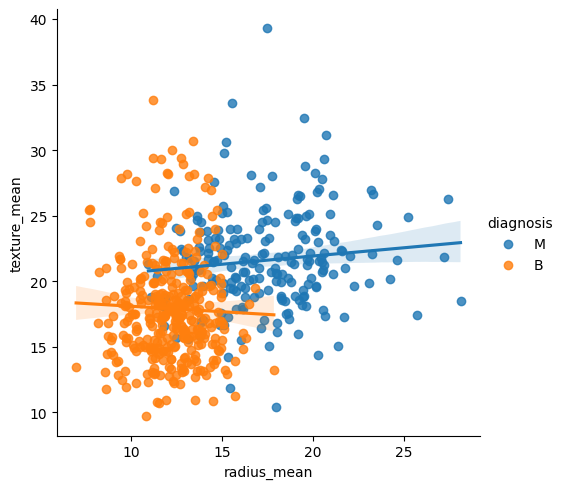

In [20]:
import seaborn as sns

sns.lmplot(x='radius_mean', y='texture_mean', hue='diagnosis', data=df)

## Visualización: Suavidad Media vs Compacidad Media

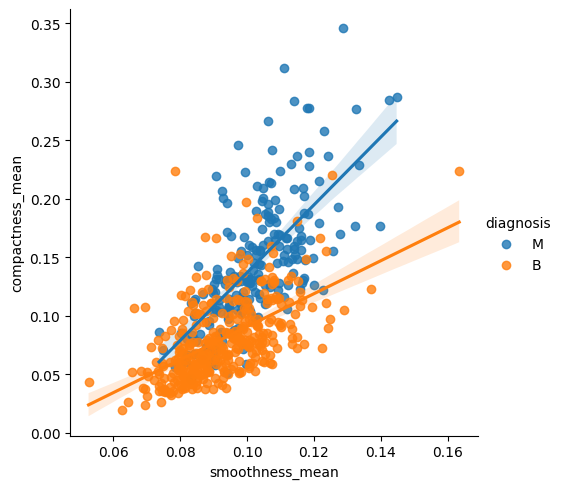

In [21]:
sns.lmplot(x='smoothness_mean', y='compactness_mean',
           data=df, hue='diagnosis')

### 4. División de Datos para Entrenamiento y Prueba

- **`train_test_split`**: Esta función divide los datos en dos partes: una para entrenar el modelo y otra para probarlo.
- **`test_size=0.15`**: El 15% de los datos se usará para prueba y el 85% para entrenamiento.
- **`x_train = x_train.T`**: La **transposición** (`T`) asegura que los datos tengan la forma correcta para las operaciones matriciales durante la regresión logística.

In [34]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.15, random_state=42)

x_train = x_train.T
x_test = x_test.T
y_train = y_train.T
y_test = y_test.T

print("x train: ", x_train.shape)
print("x test:  ", x_test.shape)
print("y train: ", y_train.shape)
print("y test:  ", y_test.shape)

x train:  (30, 483)
x test:   (30, 86)
y train:  (483,)
y test:   (86,)


**Salida esperada:**
```
x train:  (30, 483)
x test:   (30, 86)
y train:  (483,)
y test:   (86,)
```

### 5. Inicialización de la Arquitectura del Modelo

**Inicialización de Pesos y Sesgo (Bias)**

In [23]:
def initialize_weights_and_bias(dimension):
    w = np.random.randn(dimension, 1) * 0.01
    b = 0.0
    return w, b

**Función Sigmoide para calcular el valor z**

- **`sigmoid()`**: Comprime el valor de entrada `z` entre 0 y 1, haciéndolo adecuado para clasificación binaria.

In [24]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

**Propagación Hacia Adelante y Hacia Atrás (Forward-Backward Propagation)**

- **`np.dot(w.T, x_train)`**: Realiza la multiplicación matricial de los pesos y los datos de entrada.
- **`cost`**: Mide la diferencia entre la probabilidad predicha (`y_head`) y la etiqueta real (`y_train`).
- **`derivative_weight`**: Calcula el gradiente del costo respecto a los pesos `w`. Indica cuánto debemos cambiar los pesos para reducir el costo.
- **`derivative_bias`**: Calcula el gradiente del costo respecto al sesgo `b`. Es simplemente el promedio de la diferencia entre las probabilidades predichas y las etiquetas reales.

In [25]:
def forward_backward_propagation(w, b, x_train, y_train):
    m = x_train.shape[1]
    z = np.dot(w.T, x_train) + b
    y_head = sigmoid(z)

    cost = (-1/m) * np.sum(y_train * np.log(y_head) + (1 - y_train) * np.log(1 - y_head))

    derivative_weight = (1/m) * np.dot(x_train, (y_head - y_train).T)
    derivative_bias = (1/m) * np.sum(y_head - y_train)

    gradients = {"derivative_weight": derivative_weight, "derivative_bias": derivative_bias}
    return cost, gradients

**Actualización de Parámetros**

- **`w -= learning_rate * gradients["derivative_weight"]`** y **`b -= learning_rate * gradients["derivative_bias"]`**: El peso `w` y el sesgo `b` se actualizan restando el gradiente escalado por la tasa de aprendizaje.

In [26]:
def update(w, b, x_train, y_train, learning_rate, num_iterations):
    costs = []
    gradients = {}
    for i in range(num_iterations):
        cost, grad = forward_backward_propagation(w, b, x_train, y_train)
        w -= learning_rate * grad["derivative_weight"]
        b -= learning_rate * grad["derivative_bias"]

        if i % 100 == 0:
            costs.append(cost)
            print(f"Costo después de la iteración {i}: {cost}")

    parameters = {"weight": w, "bias": b}
    return parameters, gradients, costs

### 6. Realizar Predicciones

- **`np.dot(w.T, x_test)`**: Realiza la multiplicación matricial entre los pesos transpuestos (`w.T`) y los datos de prueba (`x_test`).
- **`sigmoid(z)`**: Aplica la función de activación sigmoide a los valores, mapeándolos al rango `[0, 1]`.
- **`z[0, i] > 0.5`**: Si la probabilidad para la clase positiva (clase 1) es mayor que 0.5, la predicción es 1; en caso contrario, es 0.

In [27]:
def predict(w, b, x_test):
    m = x_test.shape[1]
    y_prediction = np.zeros((1, m))
    z = sigmoid(np.dot(w.T, x_test) + b)

    for i in range(z.shape[1]):
        y_prediction[0, i] = 1 if z[0, i] > 0.5 else 0

    return y_prediction

**Regresión Logística — Función Principal**

- **`logistic_regression(..., learning_rate=0.01, num_iterations=1000)`**: Ejecuta el modelo de regresión logística con los datos de entrenamiento y prueba dados, una tasa de aprendizaje de `0.01` y `1000` iteraciones de entrenamiento.

In [19]:
def logistic_regression(x_train, y_train, x_test, y_test, learning_rate=0.01, num_iterations=1000):
    dimension = x_train.shape[0]
    w, b = initialize_weights_and_bias(dimension)
    parameters, gradients, costs = update(w, b, x_train, y_train, learning_rate, num_iterations)

    y_prediction_test  = predict(parameters["weight"], parameters["bias"], x_test)
    y_prediction_train = predict(parameters["weight"], parameters["bias"], x_train)

    print(f"\n\nPrecisión en entrenamiento: {100 - np.mean(np.abs(y_prediction_train - y_train)) * 100}%")
    print(f"Precisión en prueba:        {100 - np.mean(np.abs(y_prediction_test - y_test)) * 100}%")

logistic_regression(x_train, y_train, x_test, y_test, learning_rate=0.01, num_iterations=1000)

Costo después de la iteración 0: 0.6940387773207514
Costo después de la iteración 100: 0.6662110997744903
Costo después de la iteración 200: 0.6416286956334907
Costo después de la iteración 300: 0.6191852691555525
Costo después de la iteración 400: 0.5985219225971738
Costo después de la iteración 500: 0.579440999770661
Costo después de la iteración 600: 0.56178736053444
Costo después de la iteración 700: 0.5454246193778399
Costo después de la iteración 800: 0.5302301829005988
Costo después de la iteración 900: 0.5160937580084023


Precisión en entrenamiento: 90.6832298136646%
Precisión en prueba:        89.53488372093022%


## AGREGADO: Importancia de Características al diagnosticar cáncer

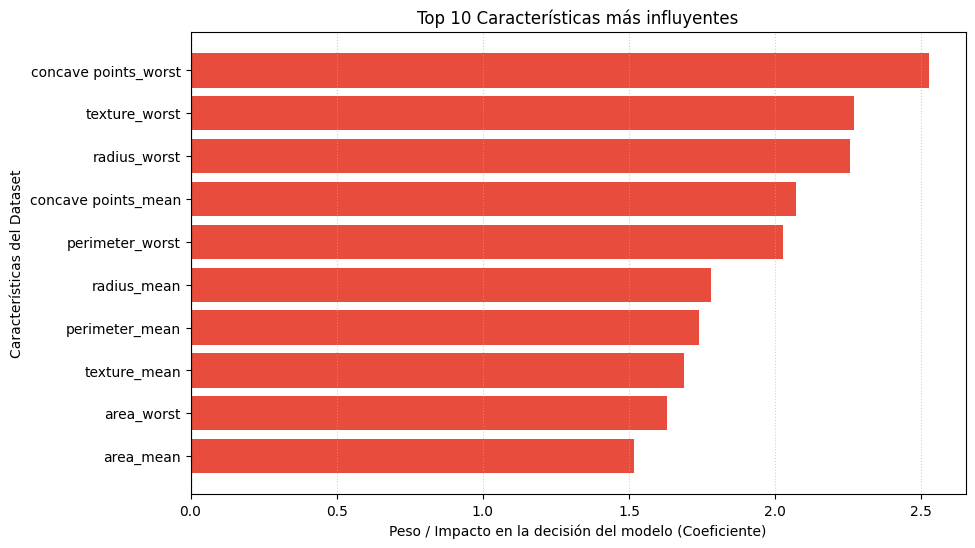

In [37]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

# Entrenar el modelo con los datos
classifier = LogisticRegression(random_state=0)
classifier.fit(x_train.T, y_train.T)

#Obtener los coeficientes del clasificador de GeeksforGeeks
# Usamos .iloc[:, 1:] para obtener los nombres de las columnas de X tal como ellos lo separaron
nombres_caracteristicas = data.iloc[:, 1:].columns
coeficientes = classifier.coef_[0]

#Crear un DataFrame para organizar los datos
df_importancias = pd.DataFrame({
    'Característica': nombres_caracteristicas,
    'Coeficiente': coeficientes
})

#Calcular el valor absoluto para ordenar por impacto real (sea positivo o negativo)
df_importancias['Abs_Coeficiente'] = df_importancias['Coeficiente'].abs()
df_importancias = df_importancias.sort_values(by='Abs_Coeficiente', ascending=False).head(10)

#Graficar los 10 factores que más afectan al modelo
plt.figure(figsize=(10, 6))

#Asignar Rojo si el coeficiente es positivo (aporta a Maligno) y Azul si es negativo (aporta a Benigno)
colores = ['#e74c3c' if c > 0 else '#3498db' for c in df_importancias['Coeficiente']]

plt.barh(df_importancias['Característica'], df_importancias['Coeficiente'], color=colores)
plt.axvline(0, color='black', linestyle='--', linewidth=0.8)

#Configuración estética de la gráfica
plt.xlabel('Peso / Impacto en la decisión del modelo (Coeficiente)')
plt.ylabel('Características del Dataset')
plt.title('Top 10 Características más influyentes')
plt.gca().invert_yaxis()  # Para que la característica más importante quede arriba
plt.grid(axis='x', linestyle=':', alpha=0.6)

plt.show()

##AGREGADO: Matriz de confusión en el diagnóstico mediante regresión logística

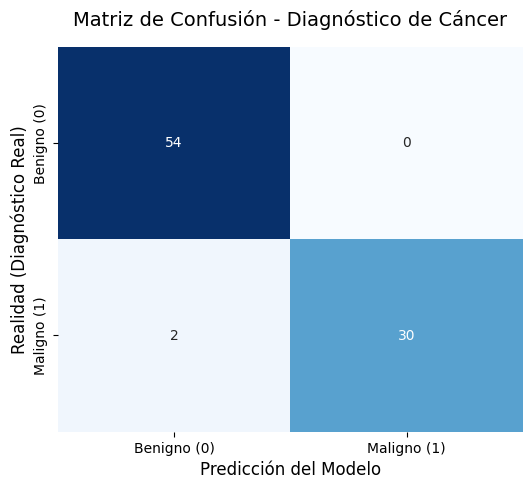


--- Reporte de Clasificación Detallado ---
              precision    recall  f1-score   support

     Benigno       0.96      1.00      0.98        54
     Maligno       1.00      0.94      0.97        32

    accuracy                           0.98        86
   macro avg       0.98      0.97      0.97        86
weighted avg       0.98      0.98      0.98        86



In [39]:
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

#Realizar las predicciones utilizando los datos de prueba (x_test)
y_pred = classifier.predict(x_test.T)

#Calcular la matriz de confusión comparando la realidad (y_test) con la predicción (y_pred)
cm = confusion_matrix(y_test.T, y_pred)

#Graficar la matriz de forma visual y elegante
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Benigno (0)', 'Maligno (1)'],
            yticklabels=['Benigno (0)', 'Maligno (1)'])

plt.title('Matriz de Confusión - Diagnóstico de Cáncer', fontsize=14, pad=15)
plt.xlabel('Predicción del Modelo', fontsize=12)
plt.ylabel('Realidad (Diagnóstico Real)', fontsize=12)
plt.show()

#Mostrar el reporte de métricas clave (Precisión, Recall, F1-Score)
print("\n--- Reporte de Clasificación Detallado ---")
print(classification_report(y_test, y_pred, target_names=['Benigno', 'Maligno']))

## Conclusión

Podemos ver que el modelo funciona correctamente, ya que la precisión de entrenamiento y prueba son similares; esto significa que el modelo puede utilizarse para la detección real del cáncer de mama.

Después de analizar el dataset, aplicar la regresión logística y evaluar el rendimiento del modelo, hemos predicho exitosamente el diagnóstico del cáncer de mama en función de las características proporcionadas. Esto demuestra la eficacia del machine learning en predicciones médicas y muestra el poder de la regresión logística en tareas de clasificación.